In [9]:
import pandas as pd

# Đọc file
df = pd.read_csv("FactAccident.csv")

# Xem qua dữ liệu
print(df.head())

           id  start_lat  start_lng  weather_conditions  fog  rain  snow  \
0  C-10152838   1.000348   1.235562                  88    0     0     0   
1  C-16760137  -0.607705   0.447920                   7    0     0     0   
2  C-23594835   0.683116   1.071714                   7    0     0     0   
3  C-24757814  -0.958212   0.105401                  14    0     0     0   
4  C-32022596  -0.625629  -1.489520                   7    0     0     0   

   hail  thunderstorm  tornado  severity  distance_mi  \
0     0             0        0  1.181436     0.545331   
1     0             0        0 -0.097353    -0.054897   
2     0             0        0 -0.097353    -0.325520   
3     0             0        0 -0.097353     0.992900   
4     0             0        0  2.460224    -1.036772   

   delayfromfreeflowspeed_mins  delayfromtypicaltraffic_mins  \
0                    -0.437970                     -0.694001   
1                     0.309673                      0.445622   
2       

In [ ]:
import pandas as pd
import numpy as np

for col in ["starttime", "endtime"]:
    df[col] = pd.to_datetime(df[col], errors='coerce')  # tránh lỗi parse

    df[f"{col}_year"] = df[col].dt.year
    df[f"{col}_month"] = df[col].dt.month
    df[f"{col}_day"] = df[col].dt.day
    df[f"{col}_hour"] = df[col].dt.hour
    df[f"{col}_minute"] = df[col].dt.minute
    df[f"{col}_second"] = df[col].dt.second

df = df.drop(columns=["starttime", "endtime"], errors='ignore')

df = df.drop(columns=["id"])




In [11]:
print(df.dtypes)

start_lat                       float64
start_lng                       float64
weather_conditions                int64
fog                               int64
rain                              int64
snow                              int64
hail                              int64
thunderstorm                      int64
tornado                           int64
severity                        float64
distance_mi                     float64
delayfromfreeflowspeed_mins     float64
delayfromtypicaltraffic_mins    float64
congestion_speed                  int64
delay_ratio                     float64
delay_per_mile                  float64
dist_freeflow                   float64
starttime_year                    int32
starttime_month                   int32
starttime_day                     int32
starttime_hour                    int32
starttime_minute                  int32
starttime_second                  int32
endtime_year                      int32
endtime_month                     int32


In [12]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['congestion_speed'])
y = df['congestion_speed']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [15]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

model = XGBClassifier(
    n_estimators=1000,
    min_child_weight=1,
    learning_rate=0.01,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,   # regularization L2
    reg_alpha=1.0,    # regularization L1
    random_state=42
)

# Huấn luyện
model.fit(X_train, y_train)
model.save_model("xgb_model.json")

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.65
[[54 18  6]
 [22 56  4]
 [ 5 15 20]]
              precision    recall  f1-score   support

           0       0.67      0.69      0.68        78
           1       0.63      0.68      0.65        82
           2       0.67      0.50      0.57        40

    accuracy                           0.65       200
   macro avg       0.65      0.63      0.64       200
weighted avg       0.65      0.65      0.65       200



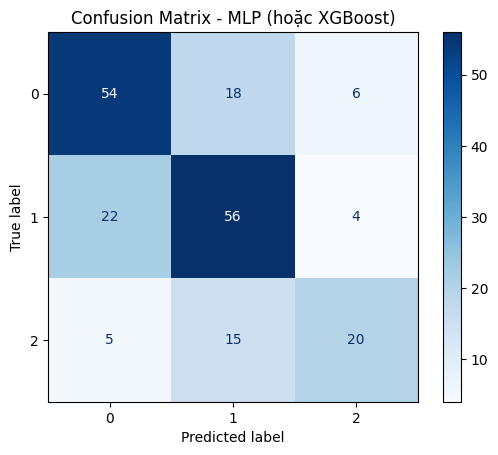

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0,1,2])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix - MLP (hoặc XGBoost)")
plt.show()


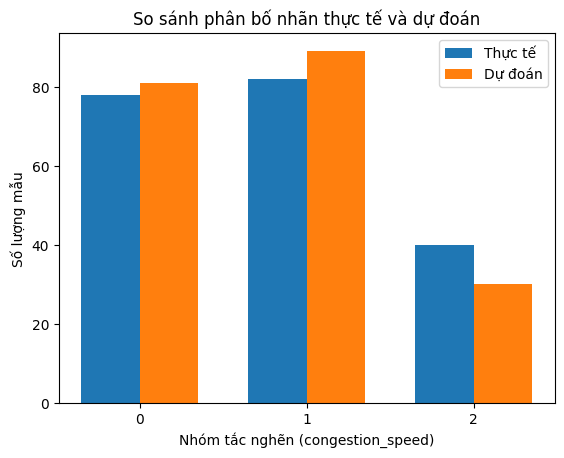

In [17]:
import numpy as np

labels = [0, 1, 2]
actual_counts = np.bincount(y_test)
pred_counts = np.bincount(y_pred)

x = np.arange(len(labels))
width = 0.35

plt.bar(x - width/2, actual_counts, width, label='Thực tế')
plt.bar(x + width/2, pred_counts, width, label='Dự đoán')
plt.xlabel("Nhóm tắc nghẽn (congestion_speed)")
plt.ylabel("Số lượng mẫu")
plt.title("So sánh phân bố nhãn thực tế và dự đoán")
plt.xticks(x, labels)
plt.legend()
plt.show()


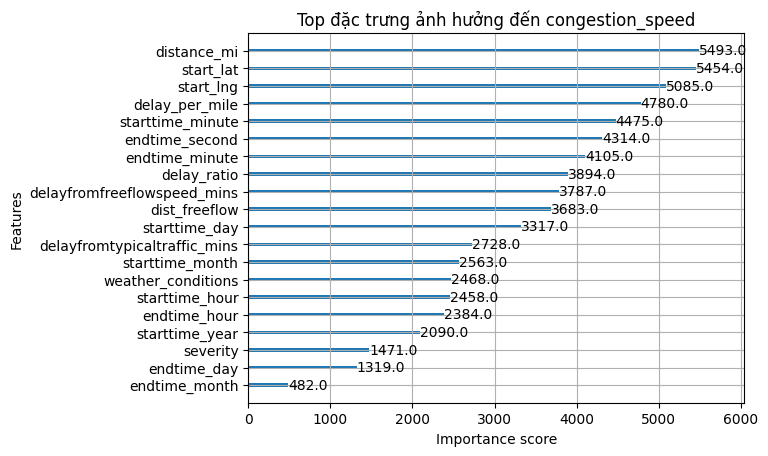

In [18]:
import matplotlib.pyplot as plt
from xgboost import plot_importance

plot_importance(model, max_num_features=20)
plt.title("Top đặc trưng ảnh hưởng đến congestion_speed")
plt.show()